In [2]:
import zipfile

zip_path = 'archive.zip'
extract_to = 'Dataset'

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_to)

print("Extraction complete!")

Extraction complete!


In [15]:
import pandas as pd
import numpy as np
from glob import glob
import cv2
import matplotlib.pyplot as plt

# Reading Images

In [16]:
dog_files=glob('Dataset/train/dog/*.jpg')
cat_files=glob('Dataset/train/cat/*.jpg')

In [17]:
img_mpl=plt.imread(cat_files[20])
img_cv2=cv2.imread(cat_files[20])

In [18]:
type(cv2.imread(cat_files[20]))


numpy.ndarray

In [19]:
img_cv2.shape, img_mpl.shape 

((334, 500, 3), (334, 500, 3))

In [20]:
# image array is height, width and channel

In [21]:
img_mpl.max() # range of pixel values is 0-255

np.uint8(255)

In [22]:
img_mpl.min()

np.uint8(0)

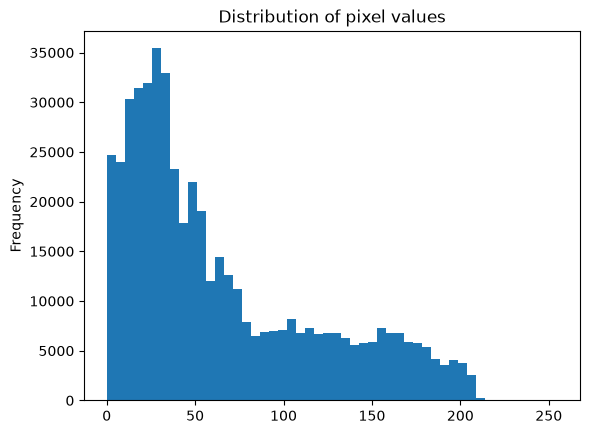

In [23]:
pd.Series(img_mpl.flatten()).plot(kind='hist',bins=50,title='Distribution of pixel values')
plt.show()

In [24]:
#Display images

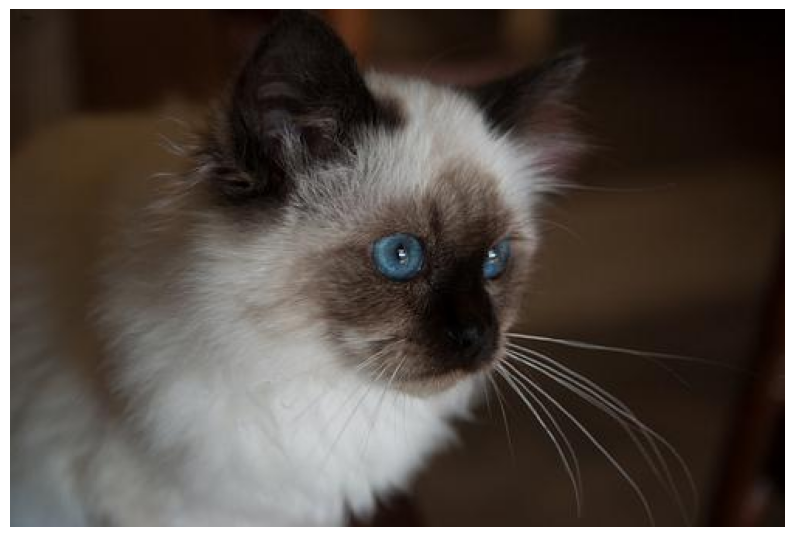

In [25]:
fig, ax=plt.subplots(figsize=(10,10))
ax.axis('off')
ax.imshow(img_mpl)

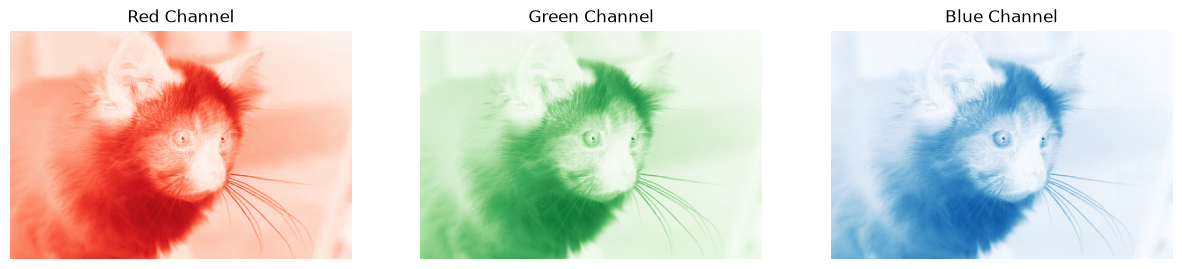

In [26]:
fig, axs=plt.subplots(1,3,figsize=(15,5))
axs[0].imshow(img_mpl[:,:,0],cmap='Reds')
axs[1].imshow(img_mpl[:,:,1],cmap='Greens')
axs[2].imshow(img_mpl[:,:,2],cmap='Blues')
axs[0].axis('off')
axs[1].axis('off')
axs[2].axis('off')
axs[0].set_title('Red Channel')
axs[1].set_title('Green Channel')
axs[2].set_title('Blue Channel')
plt.show()


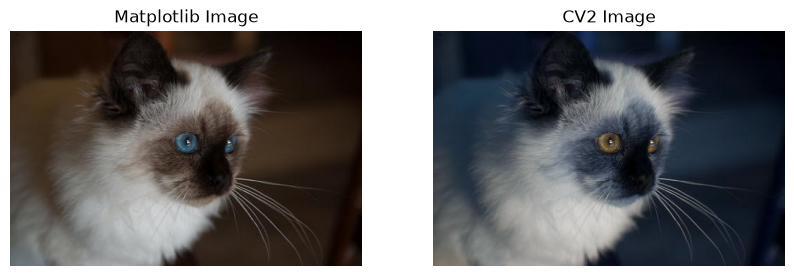

In [27]:
fig, axs=plt.subplots(1,2,figsize=(10,5))
axs[0].imshow(img_mpl) # reads RBG
axs[1].imshow(img_cv2) # reads BRG
axs[1].axis('off')
axs[0].axis('off')
axs[0].set_title('Matplotlib Image')
axs[1].set_title('CV2 Image')
plt.show()

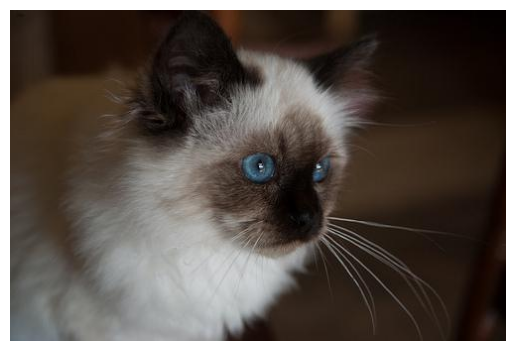

In [29]:
img_cv2_rgb=cv2.cvtColor(img_cv2, cv2.COLOR_BGR2RGB)
fig, ax=plt.subplots()
ax.imshow(img_cv2_rgb)
ax.axis('off')
plt.show()

# Image Maniplutaion

In [31]:
img=plt.imread(dog_files[4])

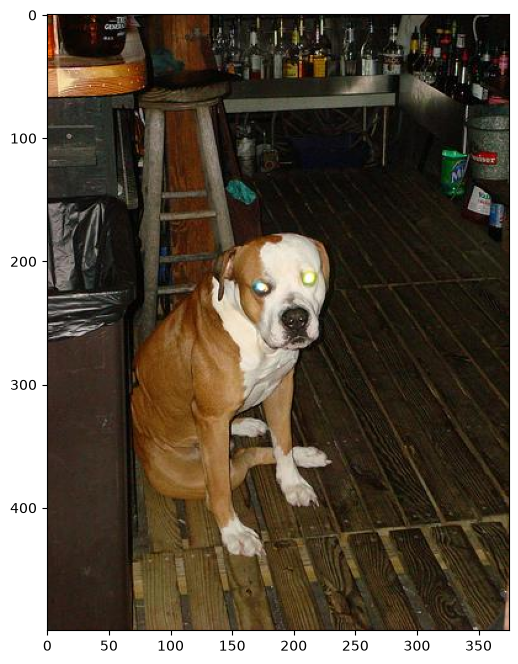

In [33]:
fig, axs=plt.subplots(figsize=(8,8))
ax.imshow(img)
ax.axis('off')
plt.imshow(img)

In [34]:
img.shape

(500, 375, 3)

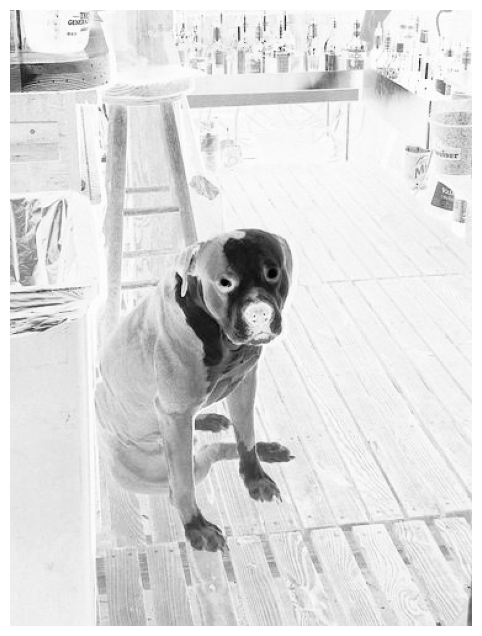

In [42]:
img_gray=cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
fig, axs=plt.subplots(figsize=(8,8))
axs.imshow(img_gray, cmap='Greys')
axs.axis('off')
plt.show()

# Resizing and Scaling

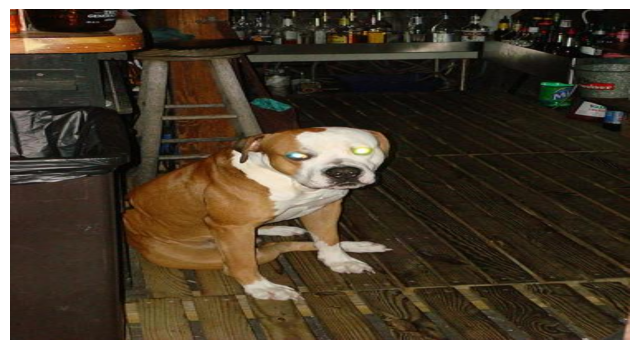

In [50]:
img_resized=cv2.resize(img, None, fx=5, fy=2)
fig, axs=plt.subplots(figsize=(8,8))
axs.imshow(img_resized)
axs.axis('off')
plt.show()

In [46]:
img_resized.shape

(125, 94, 3)

 # CV2 Kernels

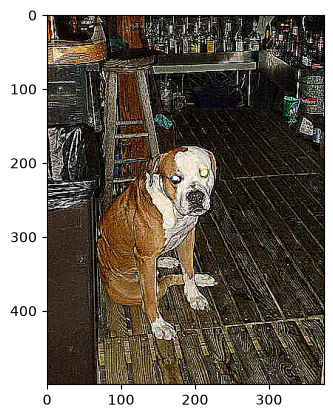

In [51]:
# Sharpening
kernel_sharpening=np.array([[-1,-1,-1],[-1,9,-1],[-1,-1,-1]])
sharpened=cv2.filter2D(img, -1, kernel_sharpening)
plt.imshow(sharpened)

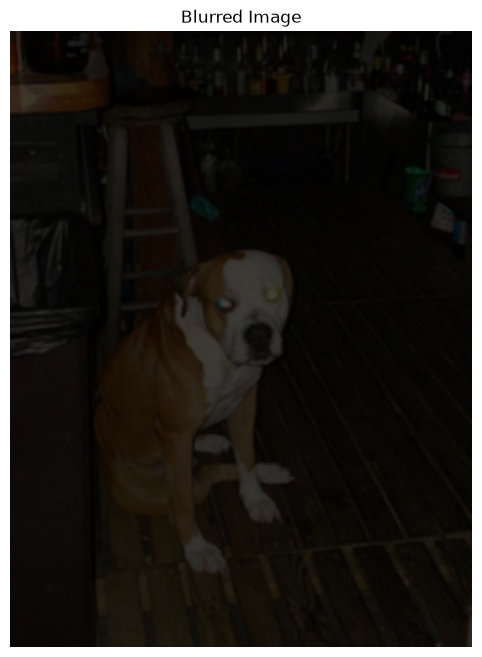

In [59]:
kernel_3x3=np.ones((3,3), np.float32)/36
blurred=cv2.filter2D(img, -1, kernel_3x3)
fig, axs=plt.subplots(figsize=(8,8))
axs.imshow(blurred)
axs.axis('off')
axs.set_title('Blurred Image')
plt.show()

# Saving Image

In [61]:
plt.imsave('mpl_dog.png', blurred)
cv2.imwrite('cv2_dog.png', blurred)

True